# Football Player Analytics

**Goal:** use player-match data to answer three questions a sports analytics team would ask:

1. **Prediction:** how well will a player perform in their *next* match?
2. **Player types:** what playing styles exist, judged only by what players do on the pitch?
3. **Scouting:** which players play like a given player, ideally for less money?

**Dataset:** [FIFA World Cup 2026 Player Performance](https://www.kaggle.com/datasets/rauffauzanrambe/fifa-world-cup-2026-player-performance-dataset) (Kaggle).
**Note:** the data is **synthetic**: 54,600 player-match rows, 1,248 players, 1,050 matches and 48 teams between 11 June and 31 July 2026 (a real World Cup has 104 matches). Results describe this simulation, not real players.

In [45]:
import kagglehub, os
path = kagglehub.dataset_download('rauffauzanrambe/fifa-world-cup-2026-player-performance-dataset')
print(path)
print(os.listdir(path))


Using Colab cache for faster access to the 'fifa-world-cup-2026-player-performance-dataset' dataset.
/kaggle/input/fifa-world-cup-2026-player-performance-dataset
['fifa_world_cup_2026_player_performance.csv']


In [46]:
import numpy as np
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import mean_absolute_error, silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans

In [47]:
import pandas as pd
DATA_PATH = os.path.join(path, 'fifa_world_cup_2026_player_performance.csv')
matches_df = pd.read_csv(DATA_PATH)
print(matches_df.shape)   # should be (54600, 75)

(54600, 75)


## Stage 1: Understanding the data
One row = **one player in one match**. Before modelling, check size, duplicates, dates and what a rating of 0 means.

In [48]:
print(matches_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54600 entries, 0 to 54599
Data columns (total 75 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   player_id                 54600 non-null  object 
 1   player_name               54600 non-null  object 
 2   age                       54600 non-null  int64  
 3   nationality               54600 non-null  object 
 4   team                      54600 non-null  object 
 5   jersey_number             54600 non-null  int64  
 6   position                  54600 non-null  object 
 7   height_cm                 54600 non-null  int64  
 8   weight_kg                 54600 non-null  int64  
 9   preferred_foot            54600 non-null  object 
 10  club_name                 54600 non-null  object 
 11  market_value_eur          54600 non-null  int64  
 12  match_id                  54600 non-null  object 
 13  match_date                54600 non-null  object 
 14  stadiu

In [50]:
matches_df['match_date'] = pd.to_datetime(matches_df['match_date'])

In [51]:
print('players (IDs):  ', matches_df['player_id'].nunique())
print('player names:   ', matches_df['player_name'].nunique())
print('matches:        ', matches_df['match_id'].nunique())
print('duplicate player-match rows:', matches_df.duplicated(subset=['player_id', 'match_id']).sum())
print('date range:', matches_df['match_date'].min().date(), 'to', matches_df['match_date'].max().date())
print('rows per player:')
print(matches_df['player_id'].value_counts().describe())

players (IDs):   1248
player names:    1245
matches:         1050
duplicate player-match rows: 0
date range: 2026-06-11 to 2026-07-31
rows per player:
count    1248.000000
mean       43.750000
std         7.033999
min        33.000000
25%        38.000000
50%        44.000000
75%        47.250000
max        66.000000
Name: count, dtype: float64


In [52]:
zero = matches_df['player_rating'] == 0
print('rows with rating 0:             ', zero.sum())
print('rating 0 but minutes played > 0:', (zero & (matches_df['minutes_played'] > 0)).sum())

rows with rating 0:              23042
rating 0 but minutes played > 0: 0


In [5]:
print(matches_df.columns.tolist())

['player_id', 'player_name', 'age', 'nationality', 'team', 'jersey_number', 'position', 'height_cm', 'weight_kg', 'preferred_foot', 'club_name', 'market_value_eur', 'match_id', 'match_date', 'stadium', 'city', 'opponent_team', 'tournament_stage', 'match_result', 'goals_team', 'goals_opponent', 'minutes_played', 'goals', 'assists', 'shots', 'shots_on_target', 'expected_goals_xg', 'expected_assists_xa', 'key_passes', 'successful_passes', 'total_passes', 'pass_accuracy', 'dribbles_attempted', 'successful_dribbles', 'crosses', 'successful_crosses', 'tackles', 'interceptions', 'clearances', 'blocks', 'aerial_duels_won', 'aerial_duels_lost', 'recoveries', 'defensive_actions', 'fouls_committed', 'fouls_suffered', 'yellow_cards', 'red_cards', 'offsides', 'saves', 'save_percentage', 'punches', 'clean_sheet', 'goals_conceded', 'penalty_saves', 'distance_covered_km', 'sprint_distance_km', 'top_speed_kmh', 'accelerations', 'decelerations', 'stamina_score', 'player_rating', 'performance_score', 'of

In [53]:
# keep only players who actually played
played_df = matches_df[matches_df['minutes_played'] > 0].copy()
played_df = played_df.sort_values(['player_id', 'match_date', 'match_id']).reset_index(drop=True)

print(played_df.shape)   # (31558, 75)
print('rows sharing a player + date with another match:',
      played_df.duplicated(subset=['player_id', 'match_date']).sum())

(31558, 75)
rows sharing a player + date with another match: 6593


### Stage 1 findings
- **Synthetic data:** 1,050 matches in 51 days and mixed-up player names. Each team plays about 44 matches, so each player has 33–66 rows.
- **No missing values and no duplicate player-match rows.**
- **1,248 player IDs but 1,245 names:** some players share a name, so `player_id` is the key throughout.
- **42% of rows (23,042) are unused squad players:** 0 minutes and a rating of 0. They are removed, leaving **31,558** played rows.
- About 21% of played rows share a date with another match by the same player (a simulation artefact). Rows are ordered by date and then `match_id` so the order is stable.
- **Leakage risk:** `total_*_tournament`, `tournament_rating` and `player_of_match_awards` are whole-tournament values that include future matches, so they are **never** used as features.

## Stage 2: Predicting next-match rating
**Rule: use only information available before kick-off.**
Lag features look back at a player's earlier matches. `shift(1)` inside `groupby('player_id')` stops each row from seeing its own match or another player's data.

In [54]:
g = played_df.groupby('player_id')

played_df['prev_rating']  = g['player_rating'].shift(1)
played_df['prev_minutes'] = g['minutes_played'].shift(1)
played_df['prev3_avg_rating'] = g['player_rating'].transform(
    lambda s: s.shift(1).rolling(3, min_periods=1).mean())
played_df['prev_all_avg_rating'] = g['player_rating'].transform(
    lambda s: s.shift(1).expanding().mean())

played_df[['player_id', 'match_date', 'player_rating',
           'prev_rating', 'prev3_avg_rating', 'prev_all_avg_rating']].head()

,player_id,match_date,player_rating,prev_rating,prev3_avg_rating,prev_all_avg_rating
0,P00001,2026-06-13,5.4,NaN,NaN,NaN
1,P00001,2026-06-19,5.7,5.4,5.400000,5.400000
2,P00001,2026-06-21,6.5,5.7,5.550000,5.550000
3,P00001,2026-06-21,6.5,6.5,5.866667,5.866667
4,P00001,2026-06-29,4.8,6.5,6.233333,6.025000


**Time-based split:** train on earlier dates and test on later ones (about 80/20). A random split would let the model learn from future matches.

In [55]:
model_df = played_df.dropna(subset=['prev_rating']).copy()   # drops each player's first match
cutoff = model_df['match_date'].quantile(0.8)

train_df = model_df[model_df['match_date'] <  cutoff]
test_df  = model_df[model_df['match_date'] >= cutoff]

print('rows removed (first matches):', len(played_df) - len(model_df))
print('cutoff:', cutoff.date())
print('train:', train_df.shape, '| test:', test_df.shape)
print('last train date:', train_df['match_date'].max().date(),
      '| first test date:', test_df['match_date'].min().date())

rows removed (first matches): 1248
cutoff: 2026-07-23
train: (23973, 79) | test: (6337, 79)
last train date: 2026-07-22 | first test date: 2026-07-23


**Baselines first.** A model is only useful if it beats simple rules.

In [56]:
y_train = train_df['player_rating']
y_test  = test_df['player_rating']

results = {
    'A: global mean':  mean_absolute_error(y_test, [y_train.mean()] * len(y_test)),
    'B: last-3 avg':   mean_absolute_error(y_test, test_df['prev3_avg_rating']),
    'C: career avg':   mean_absolute_error(y_test, test_df['prev_all_avg_rating']),
}
for name, mae in results.items():
    print(f'{name:<18} MAE {mae:.3f}')

A: global mean     MAE 0.593
B: last-3 avg      MAE 0.578
C: career avg      MAE 0.512


In [57]:
features = ['prev_rating', 'prev3_avg_rating', 'prev_all_avg_rating',
            'prev_minutes', 'age', 'market_value_eur', 'position']

X_train = pd.get_dummies(train_df[features], columns=['position'])
X_test  = pd.get_dummies(test_df[features],  columns=['position'])
X_test  = X_test.reindex(columns=X_train.columns, fill_value=0)   # same columns, same order

rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

results['Random forest'] = mean_absolute_error(y_test, rf.predict(X_test))
print(f"Random forest      MAE {results['Random forest']:.3f}")

Random forest      MAE 0.507


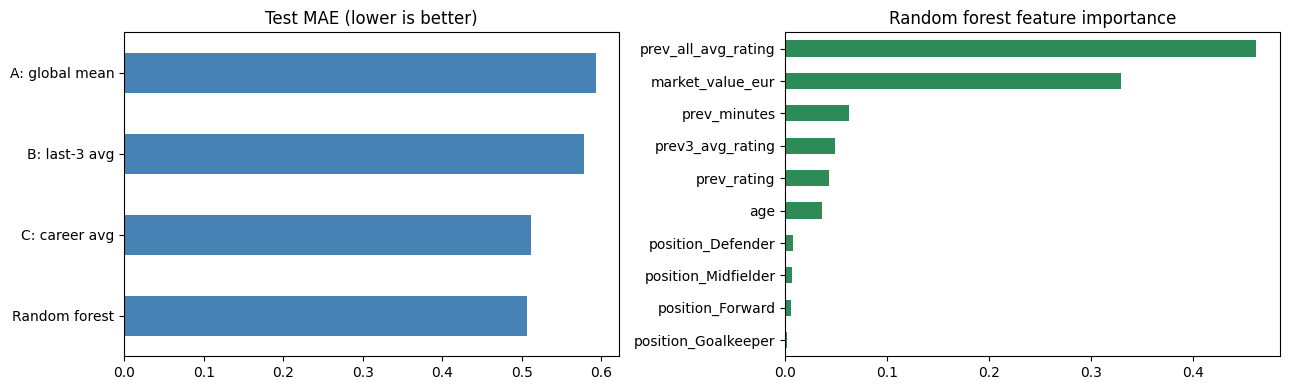

In [59]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

pd.Series(results).plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Test MAE (lower is better)')
axes[0].invert_yaxis()

importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importances.plot.barh(ax=axes[1], color='seagreen')
axes[1].set_title('Random forest feature importance')

plt.tight_layout()
plt.show()

### Stage 2 findings
| Model | Test MAE |
|---|---|
| A: global mean | 0.593 |
| B: last-3 average | 0.578 |
| C: career average | 0.512 |
| **Random forest** | **0.507** |

- Recent form (last 3) barely beats the global mean. Career-to-date average is much stronger.
- The random forest improves on the best baseline by only 0.005. **Ratings are mostly stable player ability plus match-to-match noise.**
- Feature importance: career average (≈46%) and market value (≈33%) dominate. Recent form adds little.
- Caveat: impurity-based importance can favour features with many distinct values (such as market value). Permutation importance would be a more robust check.

## Stage 3: Clustering players by playing style
Build **one row per player**, convert stats to **per 90 minutes** (fair comparison between players with different playing time) and cluster with **KMeans**.
`position` is **not** an input. It is only used afterwards to check the clusters.

In [60]:
stat_cols = ['goals', 'assists', 'shots', 'shots_on_target', 'expected_goals_xg',
             'expected_assists_xa', 'key_passes', 'successful_passes', 'total_passes',
             'dribbles_attempted', 'successful_dribbles', 'crosses', 'tackles',
             'interceptions', 'clearances', 'blocks', 'aerial_duels_won', 'recoveries']

info   = played_df.groupby('player_id')[['player_name', 'team', 'position', 'market_value_eur']].first()
totals = played_df.groupby('player_id')[stat_cols + ['minutes_played']].sum()
players_df = info.join(totals)

# outfield players with at least 3 full matches
players_df = players_df[(players_df['position'] != 'Goalkeeper') &
                        (players_df['minutes_played'] >= 270)].copy()

# per-90 conversion (built in the same cell, so re-running is safe)
players_df[stat_cols] = players_df[stat_cols].div(players_df['minutes_played'], axis=0) * 90

print(players_df.shape)
print(players_df['position'].value_counts())

(1104, 23)
position
Defender      432
Midfielder    384
Forward       288
Name: count, dtype: int64


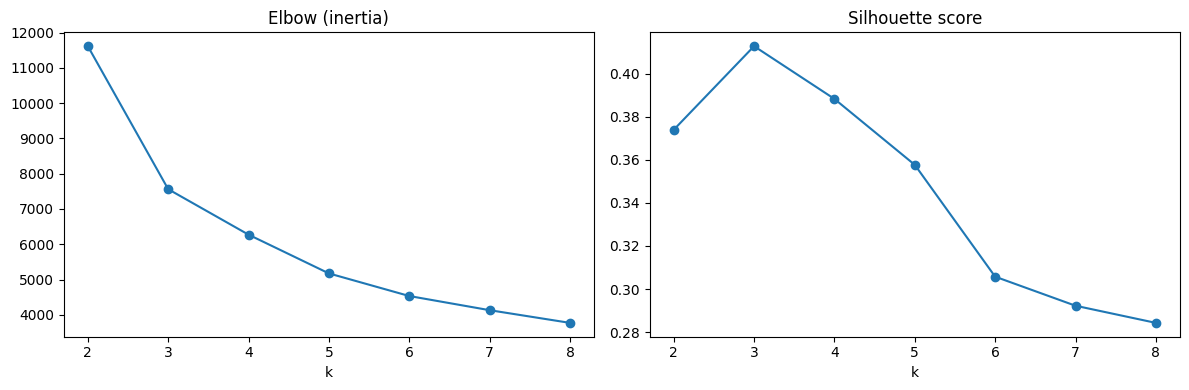

In [61]:
X = StandardScaler().fit_transform(players_df[stat_cols])   # every stat on the same scale

ks, inertias, silhouettes = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, marker='o');    axes[0].set_title('Elbow (inertia)');    axes[0].set_xlabel('k')
axes[1].plot(ks, silhouettes, marker='o'); axes[1].set_title('Silhouette score'); axes[1].set_xlabel('k')
plt.tight_layout()
plt.show()

In [62]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
players_df['cluster'] = km.fit_predict(X)

print(pd.crosstab(players_df['cluster'], players_df['position']))
print('ARI vs position:', round(adjusted_rand_score(players_df['position'], players_df['cluster']), 3))

position  Defender  Forward  Midfielder
cluster                                
0                0      288           0
1              432        0           0
2                0        0         384
ARI vs position: 1.0


In [63]:
profile = players_df.groupby('cluster')[stat_cols].mean().round(2)
profile.T

cluster,0,1,2
goals,0.34,0.05,0.12
assists,0.19,0.06,0.20
shots,2.34,0.52,1.12
shots_on_target,0.38,0.01,0.08
expected_goals_xg,0.11,0.01,0.03
expected_assists_xa,0.06,0.01,0.08
key_passes,1.41,0.54,1.90
successful_passes,24.70,40.80,51.11
total_passes,32.56,50.61,61.05
dribbles_attempted,2.76,0.51,1.88


### Stage 3 findings
- **k = 3**: the elbow in inertia and the peak silhouette score (0.41) agree.
- Without `position` as an input, the clusters match positions **perfectly (ARI 1.0)**:
  - **Forwards:** most shots (2.3/90), goals and dribbles
  - **Defenders:** most clearances (4.2/90), interceptions and tackles
  - **Midfielders:** most passes (51/90) and key passes (1.9/90), with a balance of attacking and defending
- Caveat: on real data, roles overlap (full-backs vs wingers), so a perfect ARI is unlikely. Here it mostly reflects how cleanly the synthetic generator separates positions.
- All 1,104 outfield players passed the 270-minute filter.

## Stage 4: Similar-player finder (scouting)
**Cosine similarity** on the scaled per-90 stats compares the *shape* of each player's game. 1 = identical style, 0 = unrelated.

In [64]:
sim = cosine_similarity(X)
print(sim.shape)   # every player vs every player

def find_similar(pid, n=5, max_value=None):
    """Return the n players most similar to pid, optionally under a budget (EUR)."""
    i = players_df.index.get_loc(pid)
    scores = pd.Series(sim[i], index=players_df.index).drop(pid)

    result = players_df.loc[scores.index, ['player_name', 'team', 'position', 'market_value_eur']].copy()
    result['similarity'] = scores.round(3)

    if max_value is not None:
        result = result[result['market_value_eur'] <= max_value]

    return result.sort_values('similarity', ascending=False).head(n)

(1104, 1104)


In [67]:
pid = 'P00004'
print(players_df.loc[pid, ['player_name', 'team', 'position', 'market_value_eur']], '\n')
print('Most similar:')
print(find_similar(pid), '\n')
print('Most similar under EUR 2M:')
print(find_similar(pid, max_value=2_000_000))

player_name         Kylian Camavinga
team                          France
position                    Defender
market_value_eur             3795900
Name: P00004, dtype: object 

Most similar:
                player_name      team  position  market_value_eur  similarity
player_id                                                                    
P00451        Liam Turnbull  Scotland  Defender           2354428       0.969
P00448          John Hanley  Scotland  Defender           2633214       0.969
P00789     Armando Cummings    Panama  Defender           2646500       0.965
P00524         Luis Sanchez  Colombia  Defender           3321972       0.964
P01182          Islam Touzi   Algeria  Defender           1744100       0.962 

Most similar under EUR 2M:
                 player_name     team  position  market_value_eur  similarity
player_id                                                                    
P01182           Islam Touzi  Algeria  Defender           1744100       0.962

In [68]:
# evaluate the recommender across all players
same_pos, top_sims = [], []
for p in players_df.index:
    top = find_similar(p)
    same_pos.append((top['position'] == players_df.loc[p, 'position']).mean())
    top_sims.append(top['similarity'].mean())

print('Top-5 same position:           ', round(np.mean(same_pos) * 100, 1), '%')
print('Avg top-5 similarity:          ', round(np.mean(top_sims), 3))
print('Avg similarity of random pairs:', round(sim.mean(), 3))

Top-5 same position:            100.0 %
Avg top-5 similarity:           0.922
Avg similarity of random pairs: 0.012


### Stage 4 findings
- For a €3.8M defender, the tool finds five stylistically near-identical alternatives (similarity ≥ 0.95), all **under €2M**.
- Across all 1,104 players: **100%** of the top-5 recommendations share the player's position, with mean similarity **0.92** vs **0.01** for random pairs.
- Some players share a name, so the finder works on `player_id` and shows the team alongside the name.

## Summary
1. **Next-match rating:** a leakage-free random forest (MAE 0.507) only slightly beats a career-average baseline (0.512). Player ability, not recent form, drives ratings in this data.
2. **Player styles:** KMeans on 18 per-90 metrics recovers the three outfield positions without being told them (ARI 1.0).
3. **Scouting:** a cosine-similarity finder with a budget filter returns same-role players with 0.92 average similarity.

**Limitations:** synthetic data with unusually clean position separation; same-day matches; no opponent-strength features.
**Next steps:** gradient boosting and permutation importance; opponent-strength features; Gaussian mixture clustering for players who sit between roles; a Streamlit app for the scouting tool.

In [70]:
players_df.to_csv('players.csv')          # index (player_id) is kept by default

check = pd.read_csv('players.csv')
print(check.shape)
print(check.columns[:5].tolist())
print('cluster' in check.columns, 'team' in check.columns)

(1104, 25)
['player_id', 'player_name', 'team', 'position', 'market_value_eur']
True True
